# 13. BIEs II: Compactness and the Laplace equation

In the previous chapter, we introduced Fredholm integral equations and the Nyström method for solving second-kind equations of the form $(I-K)u=f$. The Nyström method transformed this integral equation into a linear system, by replacing $K$, a continuous operator on a space of functions, with a finite-dimensional matrix. This raises the question of why and when can we make this approximation, and what is its accuracy?

To answer these questions, we introduce the notion of **compact operators**. Although they may act on infinite-dimensional spaces, they share some of the useful features of finite-dimensional matrices. This will help us understand when a second-kind integral equation has a unique solution, and why the Nyström method converges.

We will then turn to the **Laplace equation** in two dimensions. We will introduce harmonic functions, the logarithmic fundamental solution, and the divergence theorem, and calculate the normal derivative of the fundamental solution with respect to its source point. These are some of the fundamental building blocks needed to pose and solve boundary integral equations.

## 13.1 Bounded sequences and convergence

To define compactness, we first need some language for sequences in normed spaces. A function space such as

$$
X=C([a,b]),
$$

the space of continuously differentianble functions is a space in which each "point" is a function. Functions, just like vectors, can have a "length", formally called a norm, associated with the space, such as the $L_{\infty}$-norm,

$$
\|f\|_\infty=\max_{t\in[a,b]}|f(t)|.
$$

Using this notion of length, one can compute projections, e.g. functions can be orthogonal to one another. We can discuss sequences of functions in much the same way as sequences of vectors, except think of functions as infinite-dimensional vectors.

To study the behavior of integral operators, we need to introduce some concepts related to function spaces, which are defined below.

```{admonition} Definition 
A sequence $(f_n)_{n=1}^{\infty}$ in a normed space $X$ is **bounded** if there is a constant $C$ such that

$$
\|f_n\|\le C,\qquad n=1,2,\ldots.
$$
```
```{admonition} Definition
The sequence **converges** to $f\in X$ if, for every $\varepsilon>0$, there is an integer $N$ such that

$$
\|f_n-f\|<\varepsilon\qquad \text{for every }n\ge N.
$$
```

```{admonition} Definition
A **subsequence** $(f_{n_j})_{j=1}^{\infty}$ is obtained by retaining selected terms in increasing order, where $n_1<n_2<\cdots$. 
```

Now that we have defined these terms, an important theorem that links them together is the Bolzano--Weierstrass theorem: 

```{admonition} Theorem: Bolzano--Weierstrass
:class: hint
In a finite-dimensional normed space $X$, i.e. if $\mathrm{dim}(X) < \infty$, every bounded sequence has a convergent subsequence.
```

Take $X \in \mathbb{R}$, for example, let $X$ be all real numbers between 2 and 3. I can pick numbers randomly from this space, any sequence of them will be bounded (since none of the numbers are greater than 3). Therefore, given a random selection of such numbers, I can always select an infinite number of them as a subset such that they form a convergent sequence, which is quite the striking statement.  

This statement is, however, not generally true in infinite-dimensional spaces, i.e. in these spaces, boundedness of a sequence does not guarantee the existence of a convergent subsequence. Consider the functions

$$
f_n(t)=\sin(nt),\qquad 0\le t\le\pi,\quad n=1,2,\ldots.
$$

They are bounded in the norm $L^2(0,\pi)$, since

$$
\|f_n\|_{L^2}^2=\int_0^\pi \sin^2(nt)\,dt=\frac{\pi}{2}.
$$

On the other hand, orthogonality of the sine functions gives, for $n\ne m$,

$$
\|f_n-f_m\|_{L^2}^2
=\|f_n\|_{L^2}^2+\|f_m\|_{L^2}^2
=\pi.
$$

The terms of the sequence remain a fixed distance apart, therefore there cannot be a convergent subsequence in $L^2(0,\pi)$.

## 13.2 Compact operators

The operator $K$ appearing in second kind Fredholm integral equations is a so-called compact operator.

```{admonition} Definition}
Let $X$ and $Y$ be normed spaces, and let $K:X\to Y$ be a bounded linear operator. $K$ is **compact** if, for every bounded sequence $(f_n)$ in $X$, the sequence $(Kf_n)$ in $Y$ has a convergent subsequence.
```

In other words, $K$ takes bounded sequences, which may oscillate or otherwise fail to converge, and produces sequences from which we can extract convergent subsequences. A compact operator therefore behaves, in this particular sense, as if it had a finite-dimensional range.

As an example, suppose the range of a bounded operator $K$ is finite-dimensional, for example $\operatorname{rank}(K)\subseteq\mathbb{R}^N$. Every bounded sequence $(Kf_n)$ then has a convergent subsequence by the Bolzano–Weierstrass theorem. Thus every bounded finite-rank operator is compact.

However, in an infinite-dimensional normed space, the identity $I$ is not compact. Indeed, the bounded sequence of sine functions from the previous section has no convergent subsequence, and

$$
If_n=f_n.
$$

Therefore applying the identity does nothing to recover the finite-dimensional property. Second kind Fredholm equations contain an integral operator that is of the form "identity + compact", which has important implications for the Nyström discretization.

### 13.2.1 Useful properties

Compactness has some useful corollaries:

1. Compact operators are bounded. An unbounded operator could map a sequence in the unit ball to outputs of arbitrarily large norm, which could not contain a convergent subsequence.
2. The compact operators form a closed class under operator-norm limits. If $Y$ is complete, the limit in operator norm of a sequence of compact operators is also compact.
3. Nonzero eigenvalues of a compact operator are isolated. There can be only finitely many eigenvalues outside any neighborhood of zero; if there are infinitely many nonzero eigenvalues, they can accumulate only at zero.

For the integral operators encountered in the Ch. 12, we have another important fact. An operator

$$
(Ku)(t)=\int_a^b k(t,s)u(s)\,ds
$$

with a continuous kernel $k$ on $[a,b]^2$ is compact as an operator on $C([a,b])$ equipped with the supremum norm. 
Many *weakly singular* kernels, such as kernels that are continuous away from $t=s$ and satisfy

$$
|k(t,s)|\le \frac{C}{|t-s|^\delta},\qquad 0<\delta<1,
$$

also define compact integral operators on $C([a,b])$. (The diagonal singularity of these operators is integrable.)

## 13.3 The Fredholm alternative

We return to the second-kind equation

$$
(I-K)u=f,\qquad f\in X.
$$

```{admonition} Theorem: Fredholm Alternative
:class: hint

Suppose that $K:X\to X$ is compact (and $X$ is a complete normed vector space). Then exactly one of the following possibilities holds:

1. For every $f\in X$, the equation $(I-K)u=f$ has a **unique solution** $u\in X$.
2. The homogeneous equation $(I-K)u=0$ has a **nontrivial solution** $u\ne0$.
```

The second possibility is equivalent to saying that $1$ is an eigenvalue of $K$, because

$$
(I-K)u=0\quad\Longleftrightarrow\quad Ku=u.
$$

In the first case, $I-K$ has a bounded inverse. In the second case, the inhomogeneous equation may have no solution for some $f$; whenever it does have a solution, that solution is not unique.

This is analogous to the familiar result for a square matrix $A$: the linear system $A\mathbf{x}=\mathbf{b}$ has a unique solution for *every* right-hand side if and only if $A\mathbf{x}=0$ has only the trivial solution. Compactness allows us to recover this finite-dimensional alternative for operators of the form $I-K$ on an infinite-dimensional space.

### 13.3.1 Convergence of the Nyström method

In Ch. 12, we introduced quadrature-based operators $K_n$ and solved

$$
(I-K_n)u_n=f
$$

instead of $(I-K)u=f$. Assume that $I-K$ is invertible, and that the Nyström discretizations are stable: for all sufficiently large $n$, $I-K_n$ has an inverse with

$$
\|(I-K_n)^{-1}\|\le C
$$

for a constant $C$ independent of $n$. Subtracting the exact and approximate equations gives

$$
\begin{aligned}
(I-K_n)(u_n-u)
&=(K_n-K)u,\\[2pt]
u_n-u&=(I-K_n)^{-1}(K_n-K)u.
\end{aligned}
$$

Taking supremum norms, we obtain

$$
\|u_n-u\|_\infty\le C\,\|(K_n-K)u\|_\infty.
$$

The term on the right is exactly the **quadrature error** for the fixed function $s\mapsto k(t,s)u(s)$, uniformly in $t$. Thus, when the discretized equations are stable, the Nyström solution converges at the same rate as the quadrature method used for discretizing the integral equation!

For continuous kernels and standard convergent quadrature schemes, the needed stability follows from compactness, provided $I-K$ is invertible. It is not generally necessary, or true, that $\|K_n-K\|\to0$ in operator norm for ordinary Nyström quadrature.

## 13.4 The Laplace equation

We now turn from integral equations to the partial differential equation that will motivate our first boundary integral formulations.

Let $\Omega\subset\mathbb{R}^2$ be an open, bounded domain with a sufficiently regular boundary $\partial\Omega$, and let $x=(x_1,x_2)$ be a point in the plane. The **Laplacian** is

$$
\Delta=\frac{\partial^2}{\partial x_1^2}+\frac{\partial^2}{\partial x_2^2}
=\nabla\cdot\nabla.
$$

A twice continuously differentiable function $u$ is called **harmonic** in $\Omega$ if

$$
\Delta u=0\qquad\text{in }\Omega.
$$

We will use $\hat n$ to denote the **outward unit normal** on $\partial\Omega$; its length is $1$.

```{image} img/bies2_domain_normals.pdf
:width: 65%
:align: center
```

### 13.4.1 The two-dimensional fundamental solution

Consider the function

$$
g(x)=\ln\frac{1}{|x|}=-\ln|x|,
\qquad x\in\mathbb{R}^2\setminus\{0\}.
$$

We will check that it is harmonic away from the origin. It is convenient to start with $h(x)=\ln|x|$ and write

$$
h(x)=\frac12\ln(x_1^2+x_2^2).
$$

Differentiating with respect to $x_1$,

$$
\frac{\partial h}{\partial x_1}=\frac{x_1}{x_1^2+x_2^2},
\qquad
\frac{\partial^2 h}{\partial x_1^2}
=\frac{1}{x_1^2+x_2^2}-\frac{2x_1^2}{(x_1^2+x_2^2)^2}.
$$

Similarly,

$$
\frac{\partial^2 h}{\partial x_2^2}
=\frac{1}{x_1^2+x_2^2}-\frac{2x_2^2}{(x_1^2+x_2^2)^2}.
$$

Adding the two second derivatives,

$$
\Delta h=
\frac{2}{x_1^2+x_2^2}
-\frac{2(x_1^2+x_2^2)}{(x_1^2+x_2^2)^2}=0
\qquad (x\ne0).
$$

Since $g=-h$, it follows that **$\Delta g=0$ for $x\ne0$**. The function has a(n essential) singularity at the origin.


We can move the singularity from the origin to an arbitrary *source point* $y\in\mathbb{R}^2$ by replacing $x$ with $x-y$. This gives the **fundamental solution** of the two-dimensional Laplace equation, in the sign convention we will use:

$$
\Phi(x,y)=\frac{1}{2\pi}\ln\frac{1}{|x-y|},
\qquad x,y\in\mathbb{R}^2,\quad x\ne y.

$$

Here $x$ is the observation/target point and $y$ is the source point. Because translation and multiplication by a constant preserve harmonicity,

$$
\Delta_x\Phi(x,y)=0,\qquad x\ne y.
$$

In particular, $\Phi$ is harmonic away from the source, but singular at $x=y$. The following plot shows the level sets of $\Phi$ surrounding a source point.

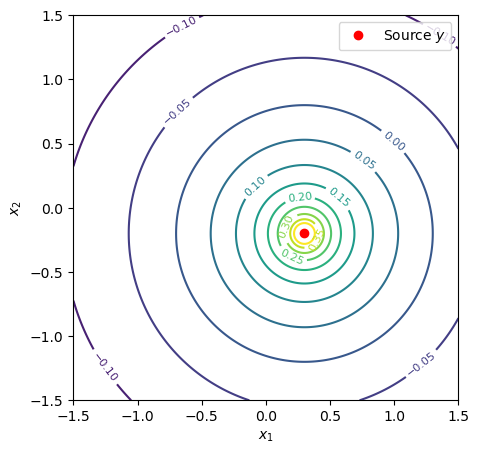

In [3]:
import numpy as np
import matplotlib.pyplot as plt

y = np.array([0.30, -0.20])  # source location
x1 = np.linspace(-1.5, 1.5, 200)
X1, X2 = np.meshgrid(x1, x1)
r = np.hypot(X1 - y[0], X2 - y[1])

# Mask a tiny neighborhood of the singularity for plotting
Phi = np.ma.masked_where(r < 0.03, -np.log(np.maximum(r, 1e-12)) / (2*np.pi))
fig, ax = plt.subplots(figsize=(5.7, 5.0))
contours = ax.contour(X1, X2, Phi, levels=np.arange(-0.15, 0.41, 0.05))
ax.clabel(contours, inline=True, fontsize=8)
ax.plot(y[0], y[1], 'ro', label='Source $y$')
ax.set(xlabel='$x_1$', ylabel='$x_2$',
       aspect='equal', xlim=(-1.5, 1.5), ylim=(-1.5, 1.5))
ax.legend(loc='upper right')
plt.show()

## 13.4.2 The normal derivative of the fundamental solution

In integral equations, both the fundamental solution above and its normal derivative is used. Let's therefore derive the normal derivative of $\Phi(x, y)$ with respect to the source point $y$, while the observation point $x$ is held fixed (a derivative with respect to $x$ can be computed similarly). Let $\hat n_y$ be a unit vector at $y$, which will later be chosen as the outward unit normal to a boundary at that point. By definition,

$$
\frac{\partial\Phi(x,y)}{\partial n_y}
=\hat n_y\cdot\nabla_y\Phi(x,y).
$$

From the previous section,

$$
\Phi(x,y)=\frac{1}{2\pi}\ln\frac{1}{|x-y|}
=-\frac{1}{4\pi}\ln\left[(x_1-y_1)^2+(x_2-y_2)^2\right].
$$

Differentiating with respect to $y_1$,

$$
\begin{aligned}
\frac{\partial}{\partial y_1}\ln\frac{1}{|x-y|}
&=-\frac12\,\frac{1}{|x-y|^2}
\frac{\partial}{\partial y_1}\left[(x_1-y_1)^2+(x_2-y_2)^2\right]\\
&=-\frac12\,\frac{-2(x_1-y_1)}{|x-y|^2}
=\frac{x_1-y_1}{|x-y|^2}.
\end{aligned}
$$

The same calculation with $y_2$ yields

$$
\nabla_y\Phi(x,y)
=\frac{1}{2\pi}\frac{x-y}{|x-y|^2},\qquad x\ne y.
$$

Therefore, the normal derivative with respect to $y$ is

$$
\frac{\partial\Phi(x,y)}{\partial n_y}
=\frac{1}{2\pi}\frac{\hat n_y\cdot(x-y)}{|x-y|^2},
\qquad x\ne y.
$$

The distinction between differentiation with respect to $x$ and $y$ matters: since $\Phi(x,y)$ depends on $x-y$, we have $\nabla_x\Phi=-\nabla_y\Phi$ for $x\ne y$. We will use the formula above when constructing boundary integral operators in the next chapters.